## 2 Global Navigation

### [2A] Module Overview

The global navigation module transforms the computer vision output into a collision-free reference trajectory. It was designed with modularity in mind, so that it is importable from anywhere. The module is spread accross multiple files for better organization and separation of concerns. The specific directory structure is shown below.

>```txt
>classes/gp/
>├── __init__.py     # init file
>├── graph.py        # VisibilityGraph class
>├── main.py         # standalone
>├── planner.py      # GlobalPlanner class
>├── plotter.py      # Plotter class
>└── utils.py        # utilities
>```

The main API used for the project are the `GlobalPlanner` and `Plotter` classes. The former houses the general planning functionality, while the latter provides useful plots: either of generated paths, or comparison plots. Import of the aforementioned classes is, as already mentioned, accessible from anywhere within the project using

In [2]:
# Module import (API used for the project)
from classes.gp import GlobalPlanner, Plotter

which exposes all the necessary functionality of global planning (and related plotting). The major ones are the `.plan()` method, owned by `GlobalPlanner`, and the `.path()` method, owned by `Plotter`.

### [2B] Independent Showcase

To show the independent functionality of the module, we provide dummy computer vision data below. Generally, the computer vision output (and thereby global planning input) obeys the following structure:

>```python
>cv_data = [
>    [W, H],                                     # map size (width, height)
>    np.array([[obs0_v0], ..., [obs0_vn]]),      # vertices of obstacle 0
>    ...,                                        # vertices of other obs.
>    np.array([[obsM_v0], ..., [obsM_vk]]),      # vertices of obstacle M
>    np.array([s_x, s_y]),                       # start coordinates (x,y)
>    np.array([g_x, g_y])                        # goal coordinates (x,y)
>]
>```

which you are free to change to get different results, but be aware of edge cases where for some maps, no path can be found. All coordinates are in the computer vision frame. Using this information, the planner computes a reference path based on a visibility graph and an A* search (to be discussed shortly).

In [4]:
import numpy as np

# Load "CV" data
data = [
        [260.0, 200.0],
        np.array([[60, 40], [90, 40], [90, 80], [60, 80]]),
        np.array([[130, 40], [200, 40], [200, 70], [130, 70]]),
        np.array([[120, 120], [160, 120], [160, 170], [120, 170]]),
        np.array([[40, 130], [70, 140], [65, 160], [35, 170], [25, 150]]),
        np.array([[200, 110], [230, 120], [220, 145]]),
        np.array([[180, 10], [230, 15], [225, 35], [175, 30]]),
        np.array([20, 20]),                                                 # change recommended
        np.array([240, 180]),                                               # change recommended
    ]

Finally, let us explore the aforementioned API. First, we need to initialize an instance of both classes. Besides the required `data` argument, the planner can also take additional arguments. Namely the Thymio's radius and the spacing of intermediate goals along the reference path. Below, you can change these values to see their effects.

In [ ]:
RADIUS = 5.0    # Thymio radius (circumscribed circle)
SPACING = 1.0   # Intermediate goals spacing

# Create GlobalPlanner instance
planner = GlobalPlanner(data, radius=RADIUS, spacing=SPACING)

# Create Plotter instance
plotter = Plotter(planner)

Notice that the instance creation of `Plotter` requires an instance of `Planner`. With both objects now initialized, a reference path can be planned and plotted using the methods mentioned above. In code:

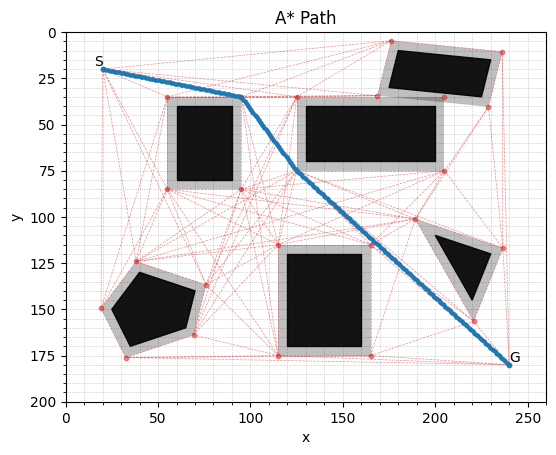

In [ ]:
segments = planner.plan()   # Plan the reference path
# plotter.plain()           # Uncomment to see plain course
# plotter.visibility()      # Uncomment to see visibility graph
plotter.path()              # Show the reference path

In addition to `.path()`, the API exposes other methods of the `Plotter` class. These allow plotting of either the plain course, or the visibility graph. Furthermore, if one has a log of robot states throughout the run, specifically the coordinates it hit, the `Plotter` API provides a `.paths()` method to overlay the robot actual path on top.

Lastly, for the case of kidnapping, the `.plan()` method of the `GlobalPlanner` class has an optional argument (`start`), which is crucial for replanning from a new position once the robot has been placed back down on the map. Notice that for replanning, no other information is required as the map size, the obstacles, and the goal position all stay constant. The replanning using a new start is shown below.

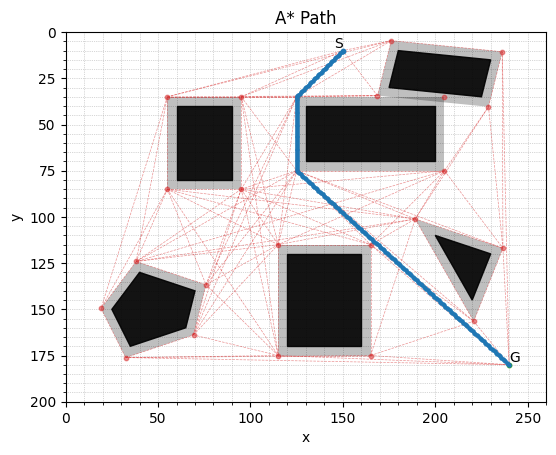

In [7]:
new_start = [150.0, 10.0]               # Choose a new start

segments2 = planner.plan(new_start)     # Replan with the new start
# plotter.plain()                       # Uncomment to see plain course
# plotter.visibility()                  # Uncomment to see visibility graph
plotter.path()                          # Update the reference path

This finalizes the independent showcase of the module. The `segments` returned by the `.plan()` method are passed on to the motion control module as goals to follow. For a deep-dive into global planning, see [2C].

### [2C] Deep-Dive & Explanation

In [ ]:
%run main.py